In [1]:
import glob
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(100)

SPLITS_DIR = sorted({p.rsplit("/", 1)[0] for p in glob.glob("/kaggle/input/**/train.parquet", recursive=True)})[0]
DEDUP = glob.glob("/kaggle/input/**/narratives_dedup.parquet", recursive=True)[0]
print("Splits :", SPLITS_DIR)
print("Corpus complet :", DEDUP)

train = pl.read_parquet(f"{SPLITS_DIR}/train.parquet")
val   = pl.read_parquet(f"{SPLITS_DIR}/val.parquet")
test  = pl.read_parquet(f"{SPLITS_DIR}/test.parquet")
print(train.shape, val.shape, test.shape)
print(train.columns)
display(train.select("complaint_id", "year", "product", "n_words", "narrative").sample(3, seed=1))

Splits : /kaggle/input/datasets/abdelbakimougari/complaintlens-splits/splits
Corpus complet : /kaggle/input/datasets/abdelbakimougari/complaintlens-data/narratives_dedup.parquet
(100000, 26) (50000, 26) (100000, 26)
['complaint_id', 'date_received', 'year', 'narrative', 'n_chars', 'n_words', 'n_masks', 'product_raw', 'product', 'sub_product', 'issue', 'sub_issue', 'company', 'company_response_to_consumer', 'timely_response', 'company_public_response', 'state', 'zip_code', 'tags', 'submitted_via', 'date_sent_to_company', 'source_export', 'text_hash', 'dup_group', 'dup_count', 'split']


complaint_id,year,product,n_words,narrative
i64,i16,str,u32,str
6470876,2023,"""credit_reporting""",91,"""Was a part of the Equifax Breech and all info exposed once again. Between Equifax and XXXX what a jo…"
5857066,2022,"""checking_savings""",110,"""I reached out to PayPal when I noticed money missing from my account. I spoke with them and filed a …"
1514114,2015,"""mortgage""",313,"""I suffered a home fire on XX/XX/XXXX ... .unbeknownst to me XXXX XXXX XXXX allowed my insurance to l…"


In [2]:
LIGHT = ["complaint_id", "date_received", "product", "company", "dup_group"]

df = (
    pl.scan_parquet(DEDUP)
    .select(LIGHT)
    .filter((pl.col("product") != "__DROP__") & (pl.col("date_received") >= pl.date(2024, 1, 1)))
    .collect()
)

# 1 récit par groupe = le plus ancien
first_ids = (
    df.filter(pl.col("dup_group").is_not_null())
    .sort(["date_received", "complaint_id"])
    .unique(subset="dup_group", keep="first")
    .select("complaint_id")
)
df = df.with_columns(
    (pl.col("dup_group").is_null() | pl.col("complaint_id").is_in(first_ids["complaint_id"].implode()))
    .alias("unique"),
    pl.col("date_received").dt.truncate("1mo").alias("month"),
)

monthly = (
    df.group_by("month", "product")
    .agg(pl.len().alias("tous"), pl.col("unique").sum().alias("uniques"))
    .sort("month", "product")
)

# Tableau : credit_reporting mois par mois
display(
    monthly.filter(pl.col("product") == "credit_reporting")
    .select("month", "tous", "uniques")
)

month,tous,uniques
date,u32,u32
2024-01-01,30666,15561
2024-02-01,34839,15685
2024-03-01,44090,18165
2024-04-01,46416,18924
2024-05-01,54569,20717
2024-06-01,54294,18408
2024-07-01,58630,20180
2024-08-01,60469,21950
2024-09-01,59698,21314


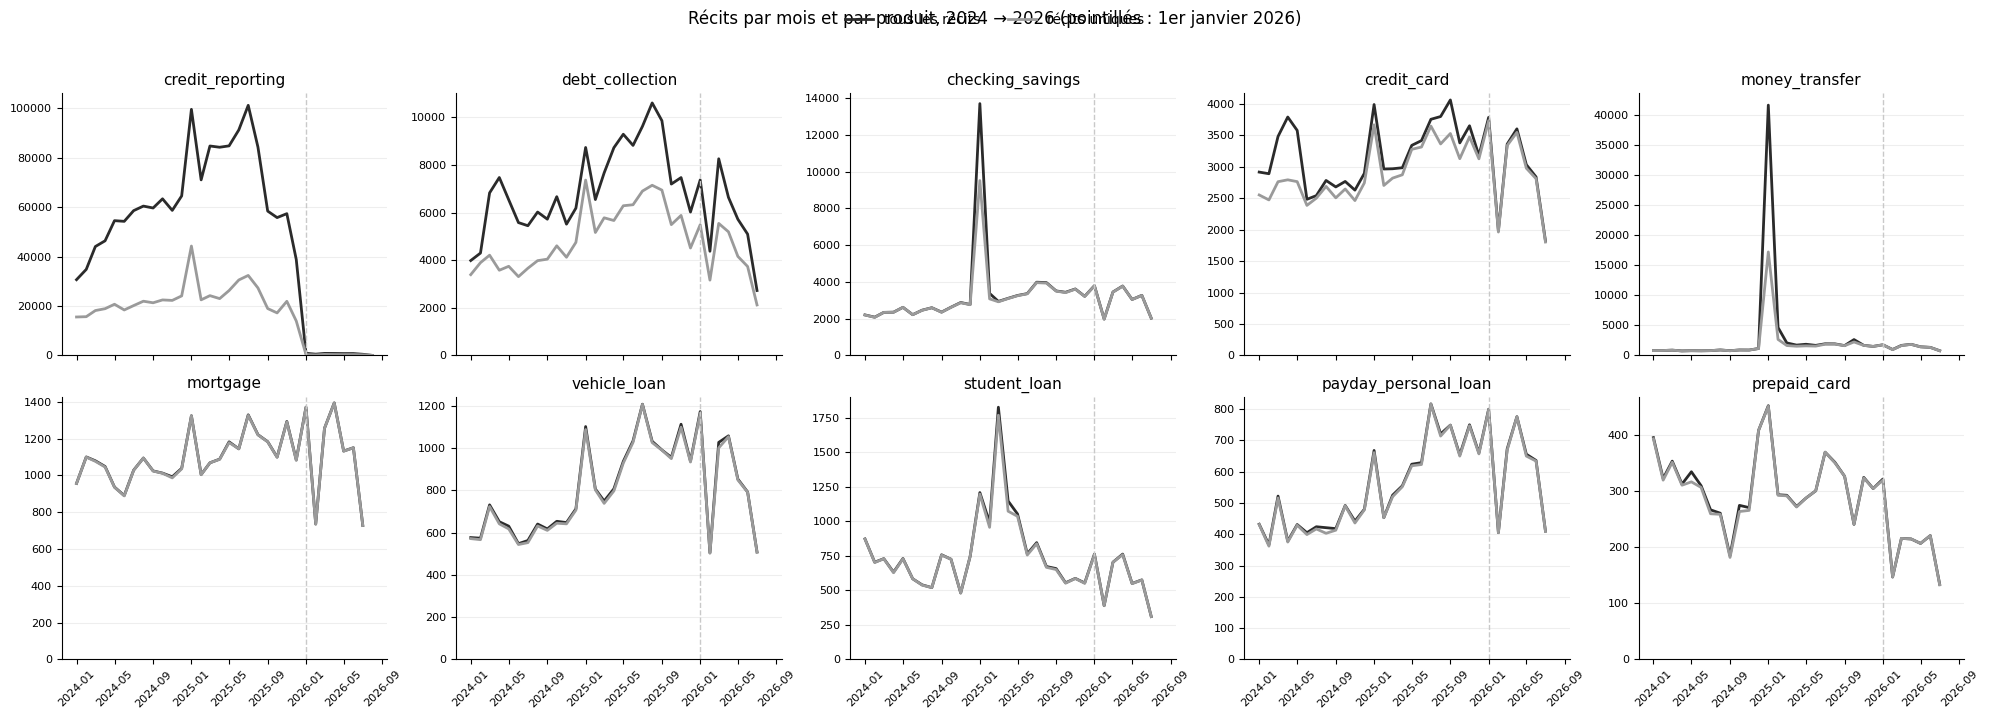

In [3]:
from datetime import date

products = (
    monthly.group_by("product").agg(pl.col("tous").sum())
    .sort("tous", descending=True)["product"].to_list()
)

fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharex=True)
for ax, p in zip(axes.flat, products):
    d = monthly.filter(pl.col("product") == p).sort("month")
    ax.plot(d["month"], d["tous"], color="#2b2b2b", lw=2, label="tous les récits")
    ax.plot(d["month"], d["uniques"], color="#9a9a9a", lw=2, label="récits uniques")
    ax.axvline(date(2026, 1, 1), color="#c9c9c9", lw=1, ls="--")
    ax.set_title(p, fontsize=11)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", color="#eeeeee")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_ylim(bottom=0)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False)
fig.suptitle("Récits par mois et par produit, 2024 → 2026 (pointillés : 1er janvier 2026)", y=1.02)
plt.tight_layout()
plt.show()

In [4]:
cr = df.filter(pl.col("product") == "credit_reporting")
top = cr.group_by("company").len().sort("len", descending=True).head(8)["company"].to_list()

by_company = (
    cr.with_columns(
        pl.when(pl.col("company").is_in(top)).then(pl.col("company")).otherwise(pl.lit("Autres"))
        .alias("entreprise"),
        pl.col("date_received").dt.year().alias("annee"),
    )
    .group_by("entreprise", "annee").len()
    .pivot(on="annee", index="entreprise", values="len", sort_columns=True)
    .fill_null(0)
    .sort("2025", descending=True)
)
display(by_company)

entreprise,2024,2025,2026
str,u32,u32,u32
"""EQUIFAX, INC.""",192303,303973,1510
"""TRANSUNION INTERMEDIATE HOLDINGS, INC.""",193198,283509,1713
"""Experian Information Solutions Inc.""",193678,259125,1380
"""Autres""",40526,50589,229
"""LEXISNEXIS""",2697,3886,34
"""CAPITAL ONE FINANCIAL CORPORATION""",3660,3839,21
"""CBC Companies, Inc.""",1532,3688,36
"""Resurgent Capital Services L.P.""",1314,2056,15
"""JPMORGAN CHASE & CO.""",1506,1481,4


In [5]:
sample = train.sample(20_000, seed=42).select("complaint_id", "product", "narrative")
N = sample.height
print(N, "récits")

20000 récits


In [6]:
AMOUNT = r"\{\$[\d,]+(?:\.\d+)?\}"

# (motif, colonne sur laquelle chercher)
PATTERNS = {
    "masque XXXX":             (r"X{2,}", "narrative"),
    "date masquée":            (r"\b(?:XX|\d{1,2})/(?:XX|\d{1,2})/(?:XXXX|\d{2,4})\b", "narrative"),
    "montant {$...}":          (AMOUNT, "narrative"),
    "nombre (hors montant)":   (r"\b\d[\d,.]*\b", "sans_montant"),
    "URL":                     (r"https?://\S+|www\.\S+", "narrative"),
    "email":                   (r"\b\S+@\S+\.\w+\b", "narrative"),
    "retour à la ligne":       (r"\n", "narrative"),
    "mot en MAJUSCULES":       (r"\b[A-WYZ][A-Z]{3,}\b", "narrative"),
    "ponctuation répétée":     (r"[!?.]{3,}", "narrative"),
    "caractère non-ASCII":     (r"[^\x00-\x7F]", "narrative"),
    "encodage cassé (â€, Ã)":  (r"â€|Ã.", "narrative"),
    "référence de loi":        (r"\b(?:FCRA|FDCPA|TILA|RESPA|U\.?S\.?C\.?|CFR)\b", "narrative"),
}

work = sample.with_columns(
    pl.col("narrative").str.replace_all(AMOUNT, " ").alias("sans_montant")
)

rows = []
for name, (pat, col) in PATTERNS.items():
    s = work.with_columns(pl.col(col).str.count_matches(pat).alias("n"))
    has = s.filter(pl.col("n") > 0)
    ctx = (
        has.head(200)
        .select(pl.col(col).str.extract(f"(.{{0,35}}(?:{pat}).{{0,35}})", 1).alias("ex"))
        .drop_nulls()["ex"].head(2).to_list()
    )
    rows.append({
        "élément": name,
        "% récits": round(has.height / N * 100, 1),
        "occurrences moy. (si présent)": round(has["n"].mean() or 0, 1),
        "exemple 1": (ctx[0] if len(ctx) > 0 else "").replace("\n", "⏎"),
        "exemple 2": (ctx[1] if len(ctx) > 1 else "").replace("\n", "⏎"),
    })

inventory = pl.DataFrame(rows)
with pl.Config(fmt_str_lengths=80, tbl_width_chars=250):
    display(inventory)

élément,% récits,occurrences moy. (si présent),exemple 1,exemple 2
str,f64,f64,str,str
"""masque XXXX""",86.1,17.7,"""XXXX XXXX XXXX XXXX XXXX XXXX, California XXXX Date of Birth : X""","""e {$790.00} for a payday loan thru XXXX. I have not taken any payday loan """
"""date masquée""",44.6,3.5,"""X, California XXXX Date of Birth : XX/XX/XXXX SS # : XXXX To Whom It May Concern""","""I sent a letter on XX/XX/XXXX to remove these incorrect name : X"""
"""montant {$...}""",36.5,3.1,"""Someone claims I owe {$790.00} for a payday loan thru XXXX. I hav""","""XXX DATE OPENED XX/XX/XXXX BALANCE {$46000.00} that is UNKNOWN to me. I came acr…"
"""nombre (hors montant)""",63.3,4.1,"""nformation on credit report ( FCRA 611 ( a ) ( 1 ) ( A ) ) : XXXX - Acco""","""me regarding a balance I owed over 3 years ago."""
"""URL""",0.6,1.1,"""ERAL TRADE COMMISSION or https : //www.ftc.gov to file a report Per FCRA section…","""DERAL TRADE COMMISION or https : //www.ftc.gov to file a report and Per FCRA sec…"
"""email""",0.0,1.0,"""by splitting my Jumbo loan of XXXX XXXX@5.25 into two loans I was promised verb""","""cer Fairway. I contacted Fairway ( servicing@fairwaymc.com ) on XX/XX/XXXX. On X…"
"""retour à la ligne""",39.3,6.5,"""responsible creditors accountable. ⏎""","""confidentiality under 15 USC 1681. ⏎"""
"""mot en MAJUSCULES""",31.6,8.4,"""er the Fair Credit Reporting Act ( FCRA ) and other applicable consumer pr""","""XX XXXX XXXX XXXX XXXXXX/XX/XXXX - UNAUTHORIZED INQUIRY has violated my rights. …"
"""ponctuation répétée""",5.9,2.2,"""... ""","""attempt to charge us for extra fees!!! Chase is practicing bad faith an"""


In [7]:
masks = (
    sample.select(pl.col("narrative").str.extract_all(r"[\w/$.,{}]*X{2,}[\w/$.,{}]*").alias("m"))
    .explode("m").drop_nulls()
    .group_by("m").len().sort("len", descending=True)
)
print(f"{masks.height} formes de masques différentes")
display(masks.head(25))

1616 formes de masques différentes


m,len
str,u32
"""XXXX""",183074
"""XXXX,""",14534
"""XX/XX/XXXX""",14529
"""XXXX.""",11453
"""XX/XX/XXXX,""",4130
"""XX/XX/XXXX.""",3782
"""XXXXXXXX""",2494
"""XX/XX/2020""",858
"""XX/XX/2022""",805


In [8]:
non_ascii = (
    sample.select(pl.col("narrative").str.extract_all(r"[^\x00-\x7F]").alias("c"))
    .explode("c").drop_nulls()
    .group_by("c").len().sort("len", descending=True)
    .with_columns(pl.col("c").map_elements(lambda ch: f"U+{ord(ch):04X}", return_dtype=pl.Utf8).alias("code"))
)
display(non_ascii.head(20))

c,len,code
str,u32,str
"""’""",16,"""U+2019"""
"""“""",4,"""U+201C"""
"""•""",2,"""U+2022"""


In [9]:
import os, sys
REPO = "/kaggle/working/ComplaintLens"
if not os.path.exists(REPO):
    !git clone -q https://github.com/AbdelBakiY/ComplaintLens.git {REPO}
!cd {REPO} && git pull -q
sys.path.insert(0, f"{REPO}/src/complaintlens/preprocessing")

import importlib, clean
importlib.reload(clean)
from clean import clean_expr

cleaned = sample.with_columns(
    clean_expr(pl.col("narrative"), "light").alias("light"),
    clean_expr(pl.col("narrative"), "full").alias("full"),
)

# Avant / après sur 3 récits
for r in cleaned.sample(3, seed=3).iter_rows(named=True):
    print("BRUT  :", r["narrative"][:400].replace("\n", "⏎"))
    print("LIGHT :", r["light"][:400])
    print("FULL  :", r["full"][:400])
    print("-" * 100)

# Effet global
stats = cleaned.select(
    pl.col("narrative").str.split(" ").list.len().mean().alias("mots_brut"),
    pl.col("light").str.split(" ").list.len().mean().alias("mots_light"),
    pl.col("full").str.split(" ").list.len().mean().alias("mots_full"),
    pl.col("light").str.count_matches(r"\[PII\]").mean().alias("MASK_par_recit"),
    pl.col("light").str.count_matches(r"\[DATE\]").mean().alias("DATE_par_recit"),
    pl.col("light").str.count_matches(r"\[MONEY\]").mean().alias("MONEY_par_recit"),
    pl.col("light").str.contains(r"X{2,}").mean().mul(100).alias("pct_masques_restants"),
)
display(stats)

BRUT  : XXXX is had me in a never ending rabbit hole to verifying my documents they have had for XXXX  months for a XXXX verifi action claim. I call daily nothing getting done. They are to open a window retroactively because I received only about half or less of my XXXX week XXXX claim because of ID verification. DURING THIS MY MOTHER PASSED AWAY. I NEEDED THE XXXX CLAIM THEN WAS XXXX IT AND HAVE BEEN WAI
LIGHT : [PII] is had me in a never ending rabbit hole to verifying my documents they have had for [PII] months for a [PII] verifi action claim. I call daily nothing getting done. They are to open a window retroactively because I received only about half or less of my [PII] week [PII] claim because of ID verification. DURING THIS MY MOTHER PASSED AWAY. I NEEDED THE [PII] CLAIM THEN WAS [PII] IT AND HAVE BE
FULL  : [PII] is had me in a never ending rabbit hole to verifying my documents they have had for [PII] months for a [PII] verifi action claim. i call daily nothing getting done. the

mots_brut,mots_light,mots_full,MASK_par_recit,DATE_par_recit,MONEY_par_recit,pct_masques_restants
f64,f64,f64,f64,f64,f64,f64
217.41475,214.0275,214.1584,5.8061,1.58495,1.11945,0.0


In [10]:
import os, sys, importlib
REPO = "/kaggle/working/ComplaintLens"
if not os.path.exists(REPO):
    !git clone -q https://github.com/AbdelBakiY/ComplaintLens.git {REPO}
!cd {REPO} && git pull -q
sys.path.insert(0, f"{REPO}/src/complaintlens/preprocessing")
import clean; importlib.reload(clean)
from clean import clean_expr

tr_texts = train.sample(20_000, seed=42).select(clean_expr(pl.col("narrative"), "light"))["narrative"].to_list()
va_texts = val.sample(5_000, seed=42).select(clean_expr(pl.col("narrative"), "light"))["narrative"].to_list()
print(len(tr_texts), len(va_texts))
print(tr_texts[0][:300])

20000 5000
[PII] , California [PII] Date of Birth : [DATE] SS # : [PII] To Whom It May Concern, I am writing to formally dispute several inaccuracies and violations present on my credit report, and to request your intervention and enforcement of my legal rights under the Fair Credit Reporting Act ( FCRA ) and 


In [11]:
import numpy as np
import spacy
from transformers import AutoTokenizer
from tokenizers import AddedToken
from clean import SPECIAL_TOKENS

# spaCy : chaque token spécial devient une "exception" jamais découpée
nlp = spacy.blank("en")
for tok in SPECIAL_TOKENS:
    nlp.tokenizer.add_special_case(tok, [{"ORTH": tok}])

# Hugging Face : tokens spéciaux ajoutés au vocabulaire (jamais découpés, jamais mis en minuscules)
gpt2 = AutoTokenizer.from_pretrained("gpt2")
bert = AutoTokenizer.from_pretrained("bert-base-uncased")
gpt2.add_special_tokens({"additional_special_tokens":
                         [AddedToken(t, lstrip=True) for t in SPECIAL_TOKENS]})
bert.add_special_tokens({"additional_special_tokens": SPECIAL_TOKENS})

TOKENIZERS = {
    "espaces":        lambda t: t.split(),
    "spaCy":          lambda t: [x.text for x in nlp.tokenizer(t)],
    "BPE GPT-2":      gpt2.tokenize,
    "WordPiece BERT": bert.tokenize,
}

phrase = "I disputed the unauthorized inquiries under 15 USC 1681 with [PII] on [DATE] for [MONEY]."
for name, f in TOKENIZERS.items():
    print(f"{name:<15} {f(phrase)}")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

espaces         ['I', 'disputed', 'the', 'unauthorized', 'inquiries', 'under', '15', 'USC', '1681', 'with', '[PII]', 'on', '[DATE]', 'for', '[MONEY].']
spaCy           ['I', 'disputed', 'the', 'unauthorized', 'inquiries', 'under', '15', 'USC', '1681', 'with', '[PII]', 'on', '[DATE]', 'for', '[MONEY]', '.']
BPE GPT-2       ['I', 'Ġdisputed', 'Ġthe', 'Ġunauthorized', 'Ġinquiries', 'Ġunder', 'Ġ15', 'ĠUSC', 'Ġ16', '81', 'Ġwith', ' [PII]', 'Ġon', ' [DATE]', 'Ġfor', ' [MONEY]', '.']
WordPiece BERT  ['i', 'disputed', 'the', 'unauthorized', 'inquiries', 'under', '15', 'usc', '168', '##1', 'with', '[PII]', 'on', '[DATE]', 'for', '[MONEY]', '.']


In [12]:
words_val = sum(len(t.split()) for t in va_texts)

rows = []
for name, f in TOKENIZERS.items():
    tr_toks = [f(t) for t in tr_texts]
    va_toks = [f(t) for t in va_texts]

    vocab_train = set(tok for toks in tr_toks for tok in toks)
    n_val = sum(len(v) for v in va_toks)
    n_oov = sum(1 for toks in va_toks for tok in toks if tok not in vocab_train)
    lens = np.array([len(v) for v in va_toks])

    rows.append({
        "tokenizer": name,
        "vocab vu (train)": len(vocab_train),
        "% OOV (val)": round(n_oov / n_val * 100, 2),
        "tokens / récit": round(lens.mean(), 1),
        "médiane": int(np.median(lens)),
        "fertilité (tokens/mot)": round(n_val / words_val, 2),
        "% récits > 512": round((lens > 512).mean() * 100, 1),
    })

comparison = pl.DataFrame(rows)
display(comparison)

n_unk = sum(t.count(bert.unk_token) for t in [" ".join(bert.tokenize(x)) for x in va_texts])
print(f"Tokens [UNK] de BERT dans la val : {n_unk}")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1100 > 1024). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (730 > 512). Running this sequence through the model will result in indexing errors


tokenizer,vocab vu (train),% OOV (val),tokens / récit,médiane,fertilité (tokens/mot),% récits > 512
str,i64,f64,f64,i64,f64,f64
"""espaces""",68016,1.01,211.0,139,1.0,7.5
"""spaCy""",41161,0.48,228.1,149,1.08,8.8
"""BPE GPT-2""",25008,0.12,243.6,158,1.15,9.8
"""WordPiece BERT""",15282,0.05,246.6,160,1.17,10.3


Tokens [UNK] de BERT dans la val : 0


In [13]:
train_texts = train.select(clean_expr(pl.col("narrative"), "light"))["narrative"].to_list()
print(len(train_texts), "récits pour l'entraînement du BPE")

100000 récits pour l'entraînement du BPE


In [14]:
import time
from tokenizers import ByteLevelBPETokenizer, AddedToken

def train_bpe(texts, vocab_size):
    tok = ByteLevelBPETokenizer()
    tok.train_from_iterator(texts, vocab_size=vocab_size, min_frequency=2, show_progress=False)
    # nos tokens spéciaux : jamais découpés, l'espace qui précède est absorbé
    tok.add_special_tokens([AddedToken(t, lstrip=True) for t in SPECIAL_TOKENS])
    return tok

def measure(name, tokenize_batch, vocab_size):
    toks = tokenize_batch(va_texts)
    lens = np.array([len(t) for t in toks])
    return {
        "tokenizer": name,
        "taille vocab": vocab_size,
        "tokens / récit": round(lens.mean(), 1),
        "médiane": int(np.median(lens)),
        "fertilité": round(lens.sum() / words_val, 3),
        "% récits > 512": round((lens > 512).mean() * 100, 1),
    }

rows = [measure("GPT-2 (générique)", lambda xs: [gpt2.tokenize(x) for x in xs], len(gpt2))]
our_bpe = {}
for v in [8_000, 16_000, 30_522, 50_257]:
    t0 = time.time()
    tok = train_bpe(train_texts, v)
    our_bpe[v] = tok
    rows.append(measure(f"BPE plaintes {v // 1000}k", lambda xs, tok=tok: [e.tokens for e in tok.encode_batch(xs)], tok.get_vocab_size()))
    print(f"BPE {v:>6} entraîné en {time.time() - t0:.0f} s")

bpe_comparison = pl.DataFrame(rows).with_columns(
    ((1 - pl.col("tokens / récit") / pl.col("tokens / récit").first()) * 100).round(1).alias("gain vs GPT-2 (%)")
)
display(bpe_comparison)

BPE   8000 entraîné en 33 s
BPE  16000 entraîné en 34 s
BPE  30522 entraîné en 41 s
BPE  50257 entraîné en 44 s


tokenizer,taille vocab,tokens / récit,médiane,fertilité,% récits > 512,gain vs GPT-2 (%)
str,i64,f64,i64,f64,f64,f64
"""GPT-2 (générique)""",50263,243.6,158,1.155,9.8,0.0
"""BPE plaintes 8k""",8006,245.5,158,1.164,10.1,-0.8
"""BPE plaintes 16k""",16006,235.9,154,1.118,9.4,3.2
"""BPE plaintes 30k""",30528,232.8,152,1.103,9.1,4.4
"""BPE plaintes 50k""",50263,231.8,151,1.098,9.1,4.8


In [15]:
DOMAIN_WORDS = ["TransUnion", "Equifax", "Experian", "creditor", "delinquent", "chargeback",
                "forbearance", "garnishment", "FCRA", "FDCPA", "Zelle", "repossession",
                "unauthorized inquiries", "identity theft"]

ours = our_bpe[50_257]
for w in DOMAIN_WORDS:
    g = gpt2.tokenize(" " + w)
    o = ours.encode(" " + w).tokens
    print(f"{w:<24} GPT-2 ({len(g)}) {g}")
    print(f"{'':<24} Nous  ({len(o)}) {o}\n")

TransUnion               GPT-2 (2) ['ĠTrans', 'Union']
                         Nous  (1) ['ĠTransUnion']

Equifax                  GPT-2 (2) ['ĠEqu', 'ifax']
                         Nous  (1) ['ĠEquifax']

Experian                 GPT-2 (2) ['ĠExper', 'ian']
                         Nous  (1) ['ĠExperian']

creditor                 GPT-2 (1) ['Ġcreditor']
                         Nous  (1) ['Ġcreditor']

delinquent               GPT-2 (1) ['Ġdelinquent']
                         Nous  (1) ['Ġdelinquent']

chargeback               GPT-2 (2) ['Ġcharge', 'back']
                         Nous  (1) ['Ġchargeback']

forbearance              GPT-2 (2) ['Ġforb', 'earance']
                         Nous  (1) ['Ġforbearance']

garnishment              GPT-2 (2) ['Ġgarn', 'ishment']
                         Nous  (1) ['Ġgarnishment']

FCRA                     GPT-2 (2) ['ĠFC', 'RA']
                         Nous  (1) ['ĠFCRA']

FDCPA                    GPT-2 (3) ['ĠF', 'DC', 'PA']
             

In [16]:
os.makedirs("/kaggle/working/tokenizers", exist_ok=True)
our_bpe[30_522].save("/kaggle/working/tokenizers/bpe_complaints_30k.json")
our_bpe[50_257].save("/kaggle/working/tokenizers/bpe_complaints_50k.json")
!ls -la /kaggle/working/tokenizers

total 5692
drwxr-xr-x 2 root root    4096 Nov 12 21:00 .
drwxr-xr-x 4 root root    4096 Nov 12 21:00 ..
-rw-r--r-- 1 root root 2185055 Nov 12 21:00 bpe_complaints_30k.json
-rw-r--r-- 1 root root 3631646 Nov 12 21:00 bpe_complaints_50k.json


In [17]:
os.makedirs("/kaggle/working/reports_l1", exist_ok=True)
inventory.write_csv("/kaggle/working/reports_l1/cleaning_inventory.csv")
comparison.write_csv("/kaggle/working/reports_l1/tokenizers_comparison.csv")
bpe_comparison.write_csv("/kaggle/working/reports_l1/bpe_comparison.csv")
!ls -la /kaggle/working/reports_l1

total 20
drwxr-xr-x 2 root root 4096 Nov 12 21:00 .
drwxr-xr-x 5 root root 4096 Nov 12 21:00 ..
-rw-r--r-- 1 root root  331 Nov 12 21:00 bpe_comparison.csv
-rw-r--r-- 1 root root 1865 Nov 12 21:00 cleaning_inventory.csv
-rw-r--r-- 1 root root  263 Nov 12 21:00 tokenizers_comparison.csv


In [18]:
!python -m spacy download en_core_web_sm -q
!cd {REPO} && git pull -q
import linguistic; importlib.reload(linguistic)
from linguistic import process_texts, process_text

texts_full = train.sample(5_000, seed=42).select(clean_expr(pl.col("narrative"), "full"))["narrative"].to_list()
print(texts_full[0][:300])
print()
print(process_text(texts_full[0])[:300])

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
[PII] , california [PII] date of birth : [DATE] ss # : [PII] to whom it may concern, i am writing to formally dispute several inaccuracies and violations present on my credit report, and to request your intervention and enforcement of my legal rights under the fair credit reporting act ( fcra ) and 

[PII] california [PII] date birth [DATE] ss [PII] concern write formally dispute inaccuracy violation present credit report request intervention enforcement legal right fair credit reporting act fcra applicable consumer protection law inaccurate reporting unauthorized inquiry significant impact fina


In [19]:
import time
from collections import Counter

CONFIGS = {
    "ponctuation retirée seulement": dict(lemmatize=False, remove_stopwords=False),
    "+ mots vides retirés":           dict(lemmatize=False, remove_stopwords=True),
    "+ lemmatisation":                dict(lemmatize=True,  remove_stopwords=False),
    "+ les deux":                     dict(lemmatize=True,  remove_stopwords=True),
}

rows, outputs = [], {}
for name, cfg in CONFIGS.items():
    t0 = time.time()
    out = process_texts(texts_full, n_process=4, **cfg)
    outputs[name] = out
    toks = [o.split() for o in out]
    rows.append({
        "configuration": name,
        "vocabulaire": len({w for t in toks for w in t}),
        "tokens / récit": round(np.mean([len(t) for t in toks]), 1),
        "temps (s)": round(time.time() - t0, 1),
    })

ling_comparison = pl.DataFrame(rows)
display(ling_comparison)

print("Les 25 tokens les plus fréquents, configuration complète :")
top = Counter(w for o in outputs["+ les deux"] for w in o.split()).most_common(25)
print(top)

configuration,vocabulaire,tokens / récit,temps (s)
str,i64,f64,f64
"""ponctuation retirée seulement""",15086,201.7,51.3
"""+ mots vides retirés""",14795,94.5,50.7
"""+ lemmatisation""",11908,201.7,61.1
"""+ les deux""",11701,94.5,65.0


Les 25 tokens les plus fréquents, configuration complète :
[('[PII]', 27960), ('not', 13338), ('account', 9384), ('[NUM]', 8847), ('credit', 7382), ('[DATE]', 7350), ('[MONEY]', 5625), ('payment', 5390), ('report', 5285), ('loan', 4076), ('pay', 3943), ('bank', 3506), ('receive', 3415), ('information', 3368), ('no', 3313), ('tell', 3280), ('card', 3229), ('time', 3094), ('call', 3085), ('send', 2838), ('company', 2509), ('day', 2396), ('say', 2386), ('state', 2329), ('debt', 2327)]


In [20]:
from spacy import displacy

nlp_full = spacy.load("en_core_web_sm")    # cette fois, avec l'analyse des dépendances
doc = nlp_full("I did not authorize the charges on my credit card and the bank refused to refund me.")

display(pl.DataFrame({
    "mot":    [t.text for t in doc],
    "lemme":  [t.lemma_ for t in doc],
    "nature": [t.pos_ for t in doc],
    "mot vide": [t.is_stop for t in doc],
}))
displacy.render(doc, style="dep", jupyter=True, options={"distance": 100})

mot,lemme,nature,mot vide
str,str,str,bool
"""I""","""I""","""PRON""",true
"""did""","""do""","""AUX""",true
"""not""","""not""","""PART""",true
"""authorize""","""authorize""","""VERB""",false
"""the""","""the""","""DET""",true
"""charges""","""charge""","""NOUN""",false
"""on""","""on""","""ADP""",true
"""my""","""my""","""PRON""",true
"""credit""","""credit""","""NOUN""",false


In [21]:
ling_comparison.write_csv("/kaggle/working/reports_l1/linguistic_comparison.csv")
print('hello')

hello


### 

Tokens : 10,360,145 | Mots différents : 41,542
Pente de Zipf : -1.71  (théorie : environ -1)
Mots vus une seule fois (hapax) : 18,538 = 45 % du vocabulaire


rang,w,len
u32,str,u32
1,"""the""",450756
2,"""i""",376860
3,"""to""",365339
4,"""[PII]""",291295
5,"""and""",287323
6,"""my""",219115
7,"""a""",215220
8,"""of""",182059
9,"""that""",159525


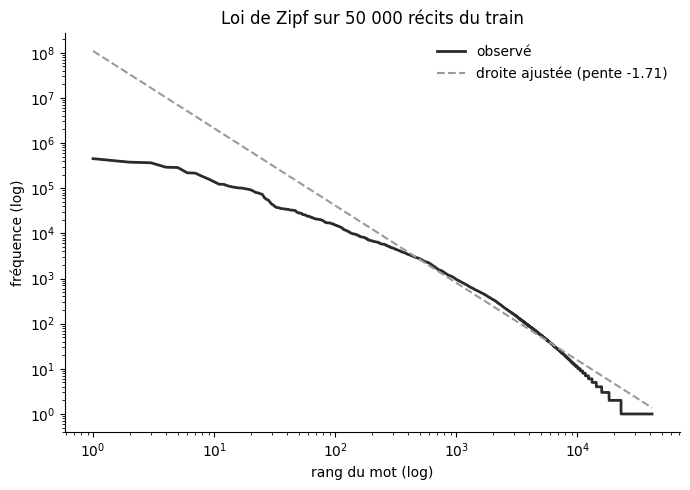

In [22]:
import re

WORD = r"\[[A-Z]+\]|[a-z_0-9']+"

docs = train.sample(50_000, seed=1).select(clean_expr(pl.col("narrative"), "full").alias("t"))
words = docs.select(pl.col("t").str.extract_all(WORD).alias("w")).explode("w").drop_nulls()
freq = (words.group_by("w").len().sort("len", descending=True)
        .with_row_index("rang", offset=1))

r, f = freq["rang"].to_numpy(), freq["len"].to_numpy()
zone = (r >= 10) & (r <= 10_000)
pente, origine = np.polyfit(np.log10(r[zone]), np.log10(f[zone]), 1)
hapax = (f == 1).sum()

print(f"Tokens : {f.sum():,} | Mots différents : {len(f):,}")
print(f"Pente de Zipf : {pente:.2f}  (théorie : environ -1)")
print(f"Mots vus une seule fois (hapax) : {hapax:,} = {hapax / len(f) * 100:.0f} % du vocabulaire")
display(freq.head(15))

fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(r, f, color="#2b2b2b", lw=2, label="observé")
ax.loglog(r, 10 ** (origine + pente * np.log10(r)), color="#9a9a9a", lw=1.5, ls="--",
          label=f"droite ajustée (pente {pente:.2f})")
ax.set_xlabel("rang du mot (log)")
ax.set_ylabel("fréquence (log)")
ax.set_title("Loi de Zipf sur 50 000 récits du train")
ax.legend(frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig("/kaggle/working/reports_l1/zipf.png", dpi=150)
plt.show()

Heaps : V = 30.8 x N^0.45
Après 10,309,949 tokens : 41,476 mots différents


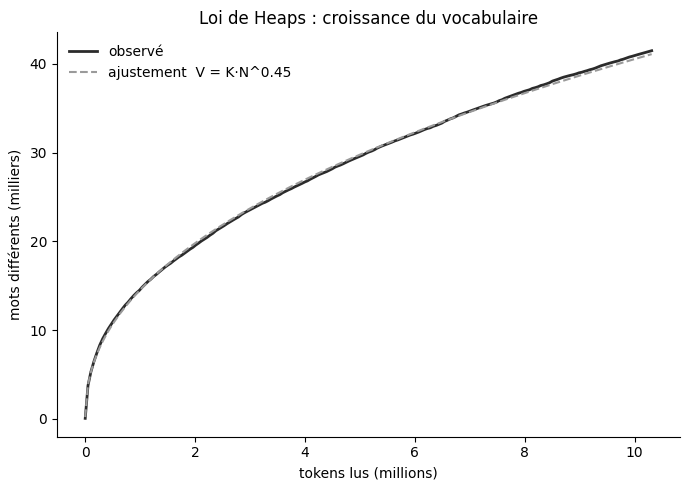

In [23]:
seen, n_tokens, points = set(), 0, []
for i, t in enumerate(docs["t"].to_list()):
    ws = re.findall(WORD, t)
    n_tokens += len(ws)
    seen.update(ws)
    if i % 250 == 0:
        points.append((n_tokens, len(seen)))

N = np.array([p[0] for p in points])
V = np.array([p[1] for p in points])
beta, logK = np.polyfit(np.log(N[1:]), np.log(V[1:]), 1)
print(f"Heaps : V = {np.exp(logK):.1f} x N^{beta:.2f}")
print(f"Après {N[-1]:,} tokens : {V[-1]:,} mots différents")

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(N / 1e6, V / 1e3, color="#2b2b2b", lw=2, label="observé")
ax.plot(N / 1e6, np.exp(logK) * N ** beta / 1e3, color="#9a9a9a", lw=1.5, ls="--",
        label=f"ajustement  V = K·N^{beta:.2f}")
ax.set_xlabel("tokens lus (millions)")
ax.set_ylabel("mots différents (milliers)")
ax.set_title("Loi de Heaps : croissance du vocabulaire")
ax.legend(frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig("/kaggle/working/reports_l1/heaps.png", dpi=150)
plt.show()

In [24]:
from collections import Counter
import math

per_class = (
    train.with_columns(pl.int_range(pl.len()).shuffle(seed=7).over("product").alias("_r"))
    .filter(pl.col("_r") < 1_000)
    .select("product", clean_expr(pl.col("narrative"), "full").alias("t"))
)
per_class = per_class.with_columns(pl.Series("proc", process_texts(per_class["t"].to_list(), n_process=4)))

MIN_COUNT = 15
rows = []
for prod in sorted(per_class["product"].unique()):
    docs_p = [d.split() for d in per_class.filter(pl.col("product") == prod)["proc"]]
    uni = Counter(w for d in docs_p for w in d)
    bi = Counter((a, b) for d in docs_p for a, b in zip(d, d[1:])
                 if not a.startswith("[") and not b.startswith("["))
    n_uni, n_bi = sum(uni.values()), sum(bi.values())
    scored = [
        (a + " " + b, c, math.log2((c / n_bi) / ((uni[a] / n_uni) * (uni[b] / n_uni))))
        for (a, b), c in bi.items() if c >= MIN_COUNT
    ]
    for expr, c, pmi in sorted(scored, key=lambda x: -x[2])[:8]:
        rows.append({"produit": prod, "collocation": expr, "occurrences": c, "PMI": round(pmi, 1)})

collocations = pl.DataFrame(rows)
with pl.Config(tbl_rows=100):
    display(collocations)

produit,collocation,occurrences,PMI
str,str,i64,f64
"""checking_savings""","""internal revenue""",22,11.9
"""checking_savings""","""driver license""",30,11.6
"""checking_savings""","""bb t""",18,10.8
"""checking_savings""","""traditional ira""",19,10.7
"""checking_savings""","""f k""",92,10.3
"""checking_savings""","""k square""",92,10.3
"""checking_savings""","""identity theft""",35,10.2
"""checking_savings""","""navy federal""",45,10.1
"""credit_card""","""goldman sachs""",25,12.0


product,n,niveau scolaire (médiane),facilité de lecture (médiane)
str,u32,f64,f64
"""credit_reporting""",1259,10.5,52.4
"""debt_collection""",769,9.2,61.7
"""credit_card""",582,9.1,64.6
"""student_loan""",303,9.1,64.1
"""money_transfer""",357,9.1,64.4
"""mortgage""",519,8.9,63.9
"""checking_savings""",483,8.9,64.6
"""vehicle_loan""",272,8.8,65.8
"""prepaid_card""",201,8.6,65.7


Global : niveau scolaire médian 9.3, facilité médiane 61.8


/tmp/ipykernel_16/3762636572.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, vert=False, labels=order, showfliers=False,


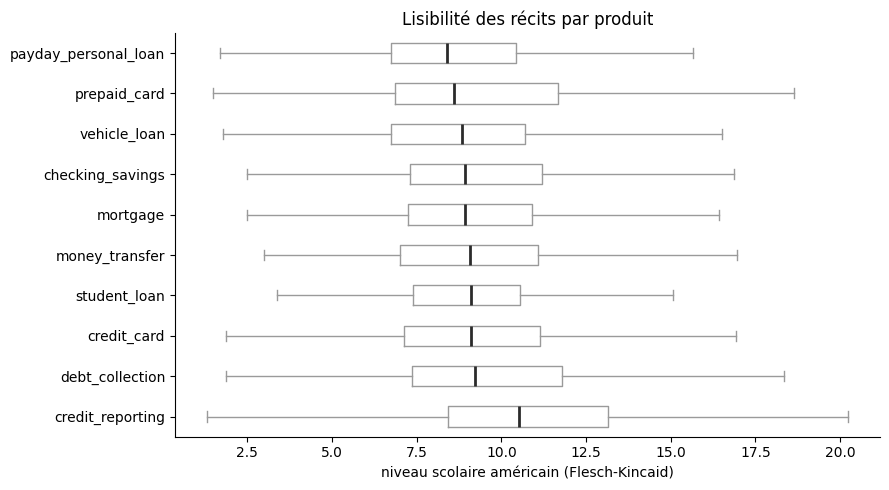

In [25]:
!pip install -q textstat
import textstat

rd = train.sample(5_000, seed=3).select(
    "product",
    clean_expr(pl.col("narrative"), "light").str.replace_all(r"\[[A-Z]+\]", "").alias("t"),
)
rd = rd.with_columns(
    pl.Series("grade", [textstat.flesch_kincaid_grade(t) for t in rd["t"]]),
    pl.Series("facilite", [textstat.flesch_reading_ease(t) for t in rd["t"]]),
)

readability = (
    rd.group_by("product")
    .agg(pl.len().alias("n"),
         pl.col("grade").median().round(1).alias("niveau scolaire (médiane)"),
         pl.col("facilite").median().round(1).alias("facilité de lecture (médiane)"))
    .sort("niveau scolaire (médiane)", descending=True)
)
display(readability)
print(f"Global : niveau scolaire médian {rd['grade'].median():.1f}, facilité médiane {rd['facilite'].median():.1f}")

order = readability["product"].to_list()
data = [rd.filter(pl.col("product") == p)["grade"].clip(0, 30).to_list() for p in order]
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(data, vert=False, labels=order, showfliers=False,
           medianprops={"color": "#2b2b2b", "lw": 2},
           boxprops={"color": "#9a9a9a"}, whiskerprops={"color": "#9a9a9a"}, capprops={"color": "#9a9a9a"})
ax.set_xlabel("niveau scolaire américain (Flesch-Kincaid)")
ax.set_title("Lisibilité des récits par produit")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig("/kaggle/working/reports_l1/readability.png", dpi=150)
plt.show()

In [26]:
freq.head(1_000).write_csv("/kaggle/working/reports_l1/zipf_top1000.csv")
pl.DataFrame({"tokens": N, "vocabulaire": V}).write_csv("/kaggle/working/reports_l1/heaps_curve.csv")
collocations.write_csv("/kaggle/working/reports_l1/collocations_pmi.csv")
readability.write_csv("/kaggle/working/reports_l1/readability.csv")
!ls -la /kaggle/working/reports_l1

total 236
drwxr-xr-x 2 root root  4096 Nov 12 21:06 .
drwxr-xr-x 5 root root  4096 Nov 12 21:00 ..
-rw-r--r-- 1 root root   331 Nov 12 21:00 bpe_comparison.csv
-rw-r--r-- 1 root root  1865 Nov 12 21:00 cleaning_inventory.csv
-rw-r--r-- 1 root root  2894 Nov 12 21:06 collocations_pmi.csv
-rw-r--r-- 1 root root  2791 Nov 12 21:06 heaps_curve.csv
-rw-r--r-- 1 root root 57785 Nov 12 21:04 heaps.png
-rw-r--r-- 1 root root   198 Nov 12 21:04 linguistic_comparison.csv
-rw-r--r-- 1 root root   347 Nov 12 21:06 readability.csv
-rw-r--r-- 1 root root 60521 Nov 12 21:06 readability.png
-rw-r--r-- 1 root root   263 Nov 12 21:00 tokenizers_comparison.csv
-rw-r--r-- 1 root root 65060 Nov 12 21:04 zipf.png
-rw-r--r-- 1 root root 16009 Nov 12 21:06 zipf_top1000.csv
